<h1 style="color:blue;text-align:center">Lógica para Ciencias de la Computación</h1>
<p style="font-size:150%;text-align:center">Entrega 3</p>
<p style="font-size:150%;text-align:center">Sistema lógico para la asignación de horarios académicos</p>
<p style="text-align:center">Jhonatan Gutiérrez Rondón | Juan Andrés Pineda</p>
<p style="text-align:center">Universidad del Rosario</p>

---

# Objetivo <a class="anchor" id="inicio"></a>

En este trabajo representamos unas reglas para asignar cursos, profesores, bloques y salones. También mostramos un horario que cumple esas reglas y convertimos la fórmula a cláusulas usando la transformación de Tseitin.

# Secciones

1. [Descripción del problema.](#prob)
2. [Las reglas y su simbolización.](#reglas)
3. [Implementación de las reglas.](#impl)
4. [Visualización.](#vis)
5. [Transformación de Tseitin.](#tseitin)
6. [Pruebas de las reglas.](#pruebas)

## Descripción del problema <a class="anchor" id="prob"></a>

([Volver al inicio](#inicio))

Hay que asignar **asignaturas**, **profesores**, **bloques horarios** y **salones** sin que se solapen y respetando las condiciones de los docentes. Todo el problema se representa con un único descriptor:

$$ASIGNAR: C\times P\times H\times S\rightarrow\{V,F\}$$

donde $ASIGNAR(c,p,h,s)=V$ si y solo si la asignatura $c$ es dictada por el profesor $p$ en el bloque $h$ y el salón $s$.

Los dominios son:

| Conjunto | Elementos | Tamaño |
|---|---|---|
| Asignaturas ($C$) | Lógica, Cálculo, Programación, Álgebra | 4 |
| Profesores ($P$) | Kurt, Bertrand, Alan | 3 |
| Bloques ($H$) | Bloque 1, Bloque 2, Bloque 3 | 3 |
| Salones ($S$) | Salón 101, Salón 102 | 2 |

El número de letras proposicionales es el producto de los tamaños: $4\times3\times3\times2=72$.

## Las reglas y su simbolización <a class="anchor" id="reglas"></a>

([Volver al inicio](#inicio))

**Regla 1 (asignación única).** Cada asignatura se programa exactamente una vez.

Al menos una asignación por curso:

$$\bigwedge_{c\in C}\left(\bigvee_{p\in P}\bigvee_{h\in H}\bigvee_{s\in S}ASIGNAR(c,p,h,s)\right)$$

A lo sumo una asignación por curso:

$$\bigwedge_{c\in C}\bigwedge_{(p,h,s)}\left(ASIGNAR(c,p,h,s)\rightarrow\neg\bigvee_{(p',h',s')\neq(p,h,s)}ASIGNAR(c,p',h',s')\right)$$

**Regla 2 (no superposición docente).** Un profesor no dicta dos asignaturas distintas en el mismo bloque:

$$\bigwedge_{p\in P}\bigwedge_{h\in H}\bigwedge_{\substack{c_1,c_2\in C\\c_1<c_2}}\bigwedge_{s_1,s_2\in S}\neg\left(ASIGNAR(c_1,p,h,s_1)\wedge ASIGNAR(c_2,p,h,s_2)\right)$$

**Regla 3 (exclusión mutua en salones).** Un salón no alberga dos asignaturas en el mismo bloque:

$$\bigwedge_{s\in S}\bigwedge_{h\in H}\bigwedge_{\substack{c_1,c_2\in C\\c_1<c_2}}\bigwedge_{p_1,p_2\in P}\neg\left(ASIGNAR(c_1,p_1,h,s)\wedge ASIGNAR(c_2,p_2,h,s)\right)$$

**Regla 4 (perfiles y disponibilidad).** Kurt solo dicta Lógica o Programación, y Bertrand no está disponible en el Bloque 1:

$$\bigwedge_{h\in H}\bigwedge_{s\in S}\left(\neg ASIGNAR(\text{Cálculo},\text{Kurt},h,s)\wedge\neg ASIGNAR(\text{Álgebra},\text{Kurt},h,s)\right)$$

$$\bigwedge_{c\in C}\bigwedge_{s\in S}\neg ASIGNAR(c,\text{Bertrand},\text{Bloque 1},s)$$

## Implementación de las reglas <a class="anchor" id="impl"></a>

([Volver al inicio](#inicio))

En Horarios.py construimos cada regla a partir de los cursos, profesores, bloques y salones. El siguiente código carga las clases y funciones que usamos:

In [6]:
# %matplotlib inline
from Horarios import *
from Logica import *

Instanciamos el objeto. Al crearlo se construye el descriptor y se generan las cuatro reglas:

In [2]:
h = Horarios()

El objeto tiene un atributo `reglas`, con las cuatro reglas como cadenas. Son muy largas, así que miramos solo su tamaño:

In [3]:
for i, r in enumerate(h.reglas, start=1):
    print(f'Regla {i}: {len(r)} caracteres')

Regla 1: 5541 caracteres
Regla 2: 1941 caracteres
Regla 3: 2913 caracteres
Regla 4: 97 caracteres


El descriptor `A` permite decodificar las letras. Por ejemplo, la letra que corresponde a (Lógica, Kurt, Bloque 1, Salón 101) es:

In [4]:
letra = h.a(0, 0, 0, 0)
print(repr(letra))
print(h.A.escribir(letra))
print(h.A.escribir('-' + letra))

'Ā'
Lógica es dictada por Kurt en el Bloque 1, Salón 101
Lógica no es dictada por Kurt en el Bloque 1, Salón 101


Las fórmulas incluyen el método `ver`, que muestra una regla en palabras. La regla 4 es la más corta, así que sirve para ver cómo se lee una regla en palabras (cada paréntesis anidado viene de un `Ytoria`):

In [4]:
A = inorder_to_tree(h.reglas[3])
print(A.ver(h.A))

((((((((((((((((((( no Cálculo es dictada por Kurt en el Bloque 1, Salón 101 Y  no Cálculo es dictada por Kurt en el Bloque 1, Salón 102) Y  no Cálculo es dictada por Kurt en el Bloque 2, Salón 101) Y  no Cálculo es dictada por Kurt en el Bloque 2, Salón 102) Y  no Cálculo es dictada por Kurt en el Bloque 3, Salón 101) Y  no Cálculo es dictada por Kurt en el Bloque 3, Salón 102) Y  no Álgebra es dictada por Kurt en el Bloque 1, Salón 101) Y  no Álgebra es dictada por Kurt en el Bloque 1, Salón 102) Y  no Álgebra es dictada por Kurt en el Bloque 2, Salón 101) Y  no Álgebra es dictada por Kurt en el Bloque 2, Salón 102) Y  no Álgebra es dictada por Kurt en el Bloque 3, Salón 101) Y  no Álgebra es dictada por Kurt en el Bloque 3, Salón 102) Y  no Lógica es dictada por Bertrand en el Bloque 1, Salón 101) Y  no Lógica es dictada por Bertrand en el Bloque 1, Salón 102) Y  no Cálculo es dictada por Bertrand en el Bloque 1, Salón 101) Y  no Cálculo es dictada por Bertrand en el Bloque 1, Salón

## Visualización <a class="anchor" id="vis"></a>

([Volver al inicio](#inicio))

Para mostrar el resultado usamos un horario de ejemplo. Antes de dibujarlo, comprobamos que la interpretación incluya las 72 posibilidades y que satisfaga las cuatro reglas.

Lógica es dictada por Kurt en el Bloque 1, Salón 101
Programación es dictada por Kurt en el Bloque 2, Salón 101
Cálculo es dictada por Alan en el Bloque 1, Salón 102
Álgebra es dictada por Bertrand en el Bloque 2, Salón 102


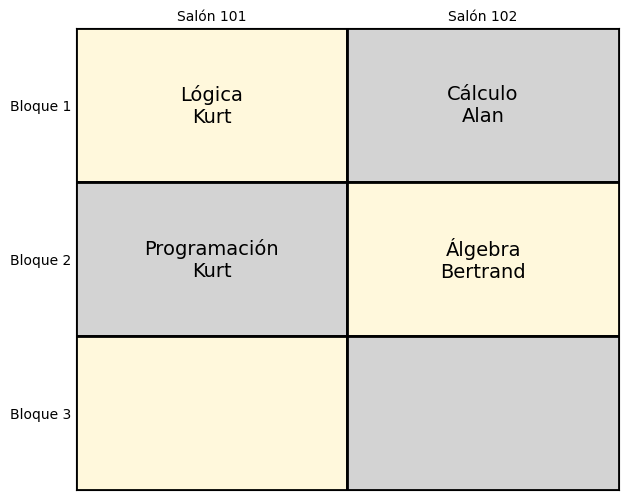

In [5]:
I = h.ejemplo()
assert inorder_to_tree(h.base_conocimiento()).valor(I)
h.imprimir(I)
h.visualizar(I)

## Transformación de Tseitin <a class="anchor" id="tseitin"></a>

([Volver al inicio](#inicio))

La base de conocimiento reúne las cuatro reglas en una sola fórmula:

In [7]:
kb = h.base_conocimiento()
print(f'La base de conocimiento tiene {len(kb)} caracteres')

La base de conocimiento tiene 10501 caracteres


La fórmula es extensa, así que aplicamos la transformación de Tseitin que hemos visto en clase. El resultado es una lista de cláusulas y una numeración para las letras proposicionales. Esta transformación prepara la fórmula para un SAT solver; aquí no implementamos la búsqueda de una interpretación porque ese paso todavía no lo hemos visto.

In [ ]:
ids, clausulas = tseitin(kb)

Cada letra proposicional queda asociada a un número. En las cláusulas, un número negativo representa la negación de esa letra. La última cláusula exige que la fórmula original sea verdadera:

In [ ]:
print(f'Átomos originales: {len(ids)}')
print(f'Cláusulas generadas: {len(clausulas)}')
print(f'Primera cláusula: {clausulas[0]}')
print(f'Cláusula de la fórmula completa: {clausulas[-1]}')

Comprobamos el horario de ejemplo evaluando las cuatro reglas juntas. El resultado debe ser True:

In [11]:
inorder_to_tree(kb).valor(I)

True

Observe que todas las asignaturas pueden quedar con un mismo profesor (por ejemplo Alan) y que Bertrand puede quedar sin clases. Esto es correcto: las reglas actuales no exigen repartir la carga entre profesores. Si se quisiera, habría que agregar una regla nueva.

## Pruebas de las reglas <a class="anchor" id="pruebas"></a>

([Volver al inicio](#inicio))

Para saber si las reglas están bien las probamos de dos maneras.

**1. Cada regla sola, con interpretaciones hechas a mano.** Cada regla se prueba con un caso que debe cumplirla y otro que debe violarla. Una regla que solo se prueba con casos que la cumplen podría estar aceptando todo.

In [12]:
from itertools import product

LOGICA, CALCULO, PROGRAMACION, ALGEBRA = 0, 1, 2, 3
KURT, BERTRAND, ALAN = 0, 1, 2

resultados = []

def interpretacion(asignaciones):
    # Los 72 átomos en falso, excepto las asignaciones (curso, profe, bloque, salón) dadas
    I = {h.a(*k): False for k in product(range(NC), range(NP), range(NH), range(NS))}
    for k in asignaciones:
        I[h.a(*k)] = True
    return I

def reporta(nombre, ok):
    resultados.append(ok)
    print(('OK     ' if ok else 'FALLA  ') + nombre)

def prueba_regla(num, asignaciones, esperado, nombre):
    f = inorder_to_tree(h.reglas[num - 1])
    reporta(f'Regla {num}: {nombre}', f.valor(interpretacion(asignaciones)) == esperado)

In [13]:
base = [(LOGICA, KURT, 0, 0), (CALCULO, ALAN, 2, 1), (PROGRAMACION, KURT, 1, 0), (ALGEBRA, ALAN, 0, 1)]

prueba_regla(1, base, True, 'un horario completo cumple')
prueba_regla(1, base[:3], False, 'falta un curso (Álgebra sin asignar)')
prueba_regla(1, base + [(LOGICA, KURT, 2, 0)], False, 'Lógica asignada dos veces')

prueba_regla(2, [(CALCULO, ALAN, 0, 0), (ALGEBRA, ALAN, 1, 1)], True, 'mismo profesor en bloques distintos cumple')
prueba_regla(2, [(CALCULO, ALAN, 0, 0), (ALGEBRA, ALAN, 0, 1)], False, 'mismo profesor, mismo bloque, salones distintos')

prueba_regla(3, [(LOGICA, KURT, 0, 0), (CALCULO, ALAN, 1, 0)], True, 'mismo salón en bloques distintos cumple')
prueba_regla(3, [(LOGICA, KURT, 0, 0), (CALCULO, ALAN, 0, 0)], False, 'mismo salón, mismo bloque, profesores distintos')

prueba_regla(4, [(LOGICA, KURT, 0, 0), (ALGEBRA, BERTRAND, 1, 0)], True, 'Kurt dicta Lógica y Bertrand en Bloque 2 cumple')
prueba_regla(4, [(CALCULO, KURT, 0, 0)], False, 'Kurt dicta Cálculo')
prueba_regla(4, [(ALGEBRA, KURT, 2, 1)], False, 'Kurt dicta Álgebra')
prueba_regla(4, [(PROGRAMACION, BERTRAND, 0, 1)], False, 'Bertrand en Bloque 1')

OK     Regla 1: un horario completo cumple
OK     Regla 1: falta un curso (Álgebra sin asignar)
OK     Regla 1: Lógica asignada dos veces
OK     Regla 2: mismo profesor en bloques distintos cumple
OK     Regla 2: mismo profesor, mismo bloque, salones distintos
OK     Regla 3: mismo salón en bloques distintos cumple
OK     Regla 3: mismo salón, mismo bloque, profesores distintos
OK     Regla 4: Kurt dicta Lógica y Bertrand en Bloque 2 cumple
OK     Regla 4: Kurt dicta Cálculo
OK     Regla 4: Kurt dicta Álgebra
OK     Regla 4: Bertrand en Bloque 1


También contamos las restricciones de las reglas 2 y 3. Hay 6 pares de cursos, así que:

- Regla 2: 3 profesores × 3 bloques × 6 pares × 4 pares de salones = 216
- Regla 3: 2 salones × 3 bloques × 6 pares × 9 pares de profesores = 324

In [14]:
reporta('Regla 2 tiene 216 restricciones', h.reglas[1].count('-(') == 216)
reporta('Regla 3 tiene 324 restricciones', h.reglas[2].count('-(') == 324)

OK     Regla 2 tiene 216 restricciones
OK     Regla 3 tiene 324 restricciones


**2. La base de conocimiento completa y la transformación.** También comprobamos que el horario de ejemplo cumpla todas las reglas y que Tseitin genere cláusulas para las 72 letras del problema.

In [ ]:
I = h.ejemplo()
formula = inorder_to_tree(kb)
reporta('el horario de ejemplo cumple todas las reglas', formula.valor(I))

ids, clausulas = tseitin(kb)
reporta('Tseitin conserva las 72 letras del problema', len(ids) == 72)
reporta('Tseitin genera cláusulas y fija la fórmula completa', bool(clausulas) and len(clausulas[-1]) == 1)

In [ ]:
print(f'{sum(resultados)} de {len(resultados)} pruebas pasaron')

---